# Energy distributions of the two high-activity spots (-82 V, DCRC1pB trigger)

*Fifth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

`positions-82v-dcrc1pb.ipynb` found two spots of high activity in the plane of the 20 % delays (`xdel`, `ydel`): one over the sector `C` and one over the centre disc `F`. Here are the energy distributions of the events in those two circles.

**The energy** of an event is the sum of the `integral` of the six channels (`Side2pA` to `Side2pF`): the sum over the whole trace of (sample - baseline), times the sample period, in ADC counts x s. It is **not calibrated**: no channel is converted to current or energy, and the channels are summed with equal weights (finding those weights is what `relcal` is for). The random triggers give a sum of about zero, so zero is the zero of this scale.

**The events** are those of the position notebook: real triggers, `total` (the sum of the positive offset-subtracted integrals) above 2, all six 20 % times present and within 60 us of each other. The circles, and the rings around them used for comparison, are defined in `spots_82v.py`, the same module the position notebook draws them from.

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spots_82v import LETTERS, SPOTS, in_spot, load, ring, series_csv

d = load()
meta = series_csv()
xdel, ydel, use, series = d["xdel"], d["ydel"], d["use"], d["series"]
E = d["integral"].sum(axis=1)                      # the energy: the sum of the six integrals (ADC counts x s)

spot = {k: use & in_spot(xdel, ydel, k) for k in SPOTS}
side = {k: use & ring(xdel, ydel, k) for k in SPOTS}
rnd = d["trigger"] == "Physics"
print(f"random triggers: {rnd.sum():,}, sum of the integrals: median {np.median(E[rnd]):+.3f}, "
      f"16-84 %: {np.percentile(E[rnd], 16):+.3f} to {np.percentile(E[rnd], 84):+.3f}")
print(f"selected events: {use.sum():,}")
for k, (x0, y0, r) in SPOTS.items():
    p = np.percentile(E[spot[k]], [10, 50, 90])
    print(f"spot {k} (centre {x0:+.2f}, {y0:+.2f} us, radius {r} us): {spot[k].sum():,} events, energy 10/50/90 %: "
          + "  ".join(f"{v:.2f}" for v in p) + f";  ring: {side[k].sum():,} events")

random triggers: 29,694, sum of the integrals: median -0.083, 16-84 %: -0.489 to +0.005
selected events: 450,703
spot C (centre +4.45, +4.80 us, radius 1.5 us): 53,567 events, energy 10/50/90 %: 5.59  9.84  12.39;  ring: 18,667 events
spot F (centre +1.60, +0.70 us, radius 1.5 us): 55,642 events, energy 10/50/90 %: 6.72  10.34  12.64;  ring: 19,561 events


## The energy distributions

Each spot against the events around it (its ring) and against all the selected events. The ring and the whole face are scaled to the number of events in the spot, so the shapes can be compared directly: where the spot rises above them, the spot has more events of that energy than its surroundings.

Two edges belong to the selection and the data, not to the spots: the low edge near 3 is the cut `total > 2`, and every distribution, the spots and the whole face alike, ends near 14.5. No channel is at its largest ADC value there, so it is not clipping of the pulses; what sets it is not known yet.

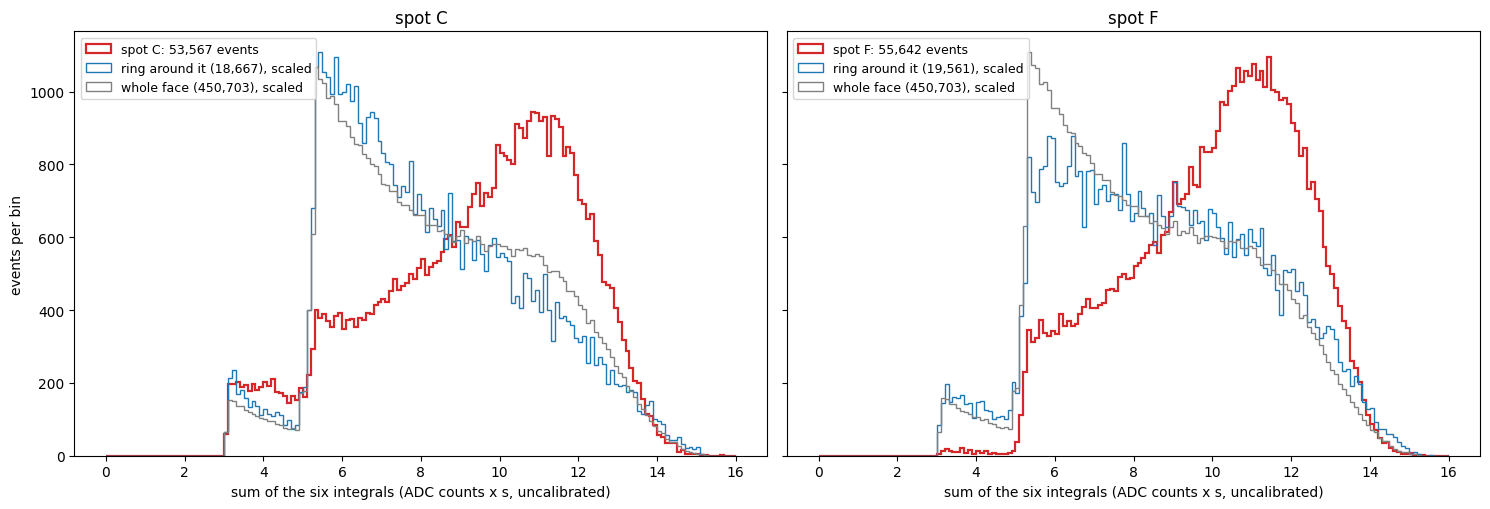

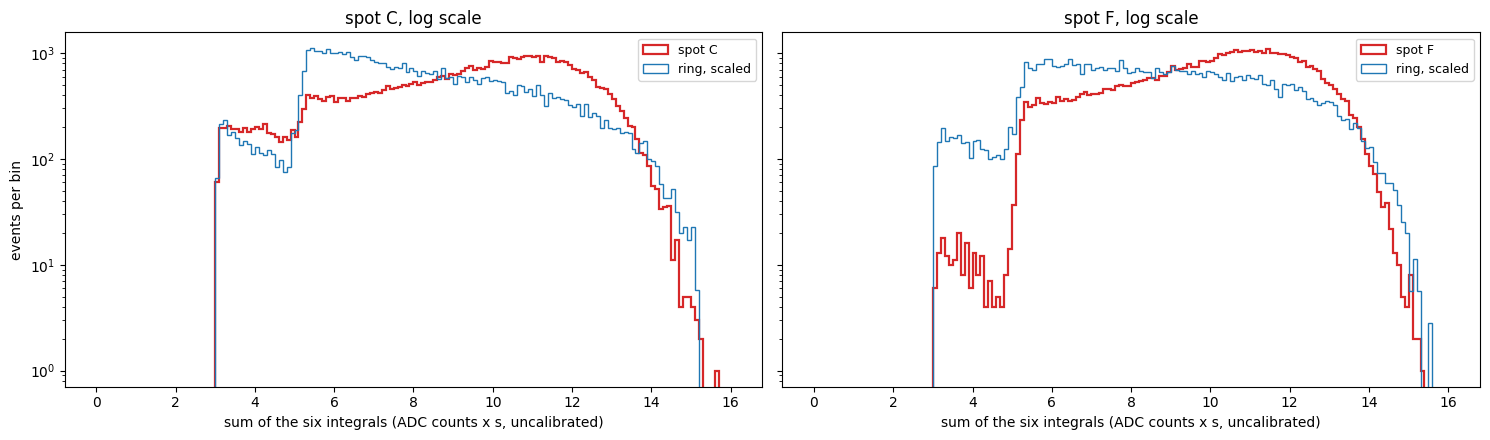

In [2]:
BINS = np.linspace(0, 16, 161)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, k in zip(axes, SPOTS):
    n_spot = spot[k].sum()
    ax.hist(E[spot[k]], bins=BINS, histtype="step", linewidth=1.6, color="C3", label=f"spot {k}: {n_spot:,} events")
    ax.hist(E[side[k]], bins=BINS, histtype="step", color="C0", weights=np.full(side[k].sum(), n_spot / side[k].sum()),
            label=f"ring around it ({side[k].sum():,}), scaled")
    ax.hist(E[use], bins=BINS, histtype="step", color="0.5", weights=np.full(use.sum(), n_spot / use.sum()),
            label=f"whole face ({use.sum():,}), scaled")
    ax.set_xlabel("sum of the six integrals (ADC counts x s, uncalibrated)")
    ax.set_title(f"spot {k}")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("events per bin")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, k in zip(axes, SPOTS):
    ax.hist(E[spot[k]], bins=BINS, histtype="step", linewidth=1.6, color="C3", label=f"spot {k}")
    ax.hist(E[side[k]], bins=BINS, histtype="step", color="C0", weights=np.full(side[k].sum(), spot[k].sum() / side[k].sum()), label="ring, scaled")
    ax.set_yscale("log")
    ax.set_xlabel("sum of the six integrals (ADC counts x s, uncalibrated)")
    ax.set_title(f"spot {k}, log scale")
    ax.legend(fontsize=9)
axes[0].set_ylabel("events per bin")
fig.tight_layout()
plt.show()

## The spot minus its surroundings

The events of a spot include the ordinary events of that place of the face. The ring estimates them: its events per unit area of the plane of the delays, times the area of the circle, are subtracted bin by bin. What remains is the excess of the spot. The error bars are the Poisson errors of both. This assumes the ordinary events are spread evenly over the circle and its ring, which is only roughly true near the centre of the face, where the density changes quickly.

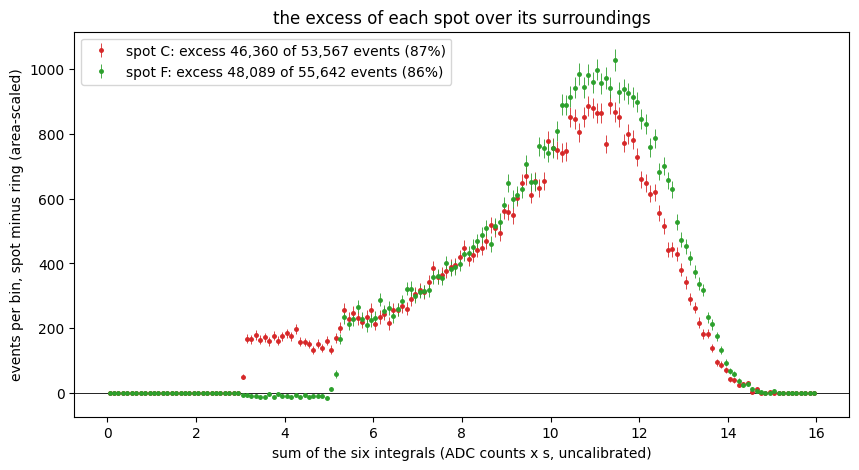

spot C: excess weighted mean energy 9.56, peak bin 11.35
spot F: excess weighted mean energy 10.19, peak bin 11.45


In [3]:
def area(k):
    r = SPOTS[k][2]
    return np.pi * r ** 2, np.pi * ((2.2 * r) ** 2 - (1.5 * r) ** 2)       # circle, ring (the defaults of spots_82v.ring)

centres = 0.5 * (BINS[1:] + BINS[:-1])
fig, ax = plt.subplots(figsize=(10, 5))
excess = {}
for k, c in zip(SPOTS, ("C3", "C2")):
    a_spot, a_ring = area(k)
    n_s, _ = np.histogram(E[spot[k]], BINS)
    n_r, _ = np.histogram(E[side[k]], BINS)
    f = a_spot / a_ring
    excess[k] = n_s - f * n_r
    err = np.sqrt(n_s + f ** 2 * n_r)
    ax.errorbar(centres, excess[k], yerr=err, fmt="o", ms=2.5, color=c, elinewidth=0.6,
                label=f"spot {k}: excess {excess[k].sum():,.0f} of {n_s.sum():,} events ({excess[k].sum() / n_s.sum():.0%})")
ax.axhline(0, color="k", linewidth=0.6)
ax.set_xlabel("sum of the six integrals (ADC counts x s, uncalibrated)")
ax.set_ylabel("events per bin, spot minus ring (area-scaled)")
ax.set_title("the excess of each spot over its surroundings")
ax.legend()
plt.show()
for k in SPOTS:
    w = np.clip(excess[k], 0, None)
    mean = (w * centres).sum() / w.sum()
    print(f"spot {k}: excess weighted mean energy {mean:.2f}, peak bin {centres[np.argmax(excess[k])]:.2f}")

## Series by series

The energy distribution of each spot in each of the eight series, normalised, to check that it does not move with the series (the HV drifts from -82.2 to -81.6 V over the five days, and the spots are not equally bright in every series: see the position notebook).

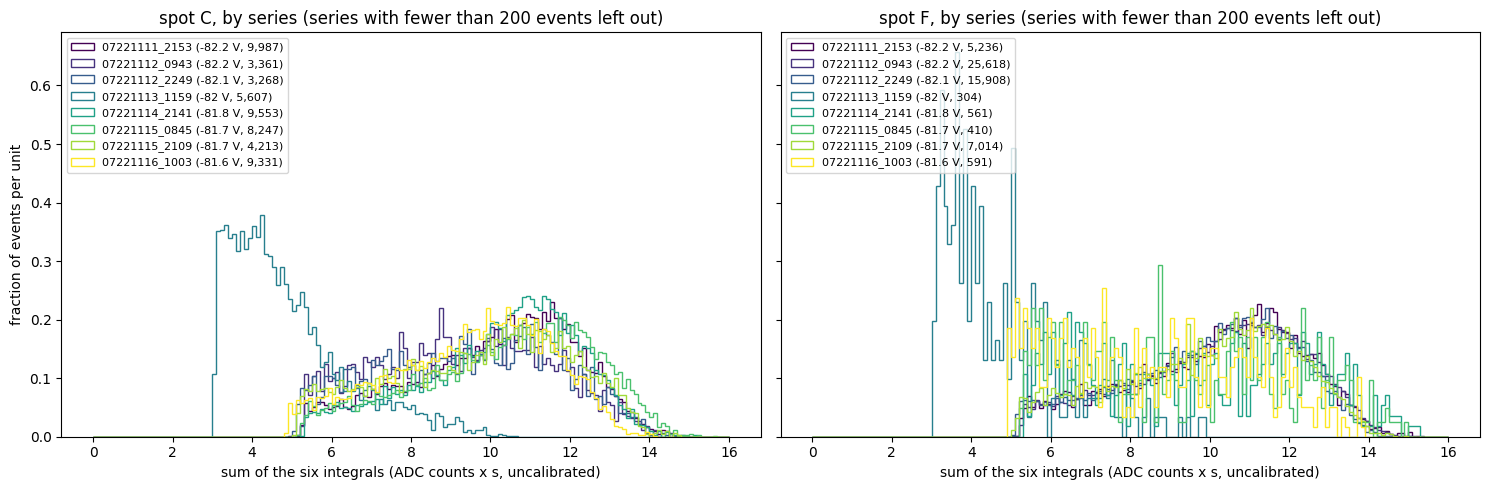

In [4]:
ss = list(np.unique(series))
cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, k in zip(axes, SPOTS):
    for i, s in enumerate(ss):
        m = spot[k] & (series == s)
        if m.sum() < 200:
            continue
        ax.hist(E[m], bins=BINS, histtype="step", density=True, color=cmap(i / (len(ss) - 1)),
                label=f"{s} ({meta[s]['HV']} V, {m.sum():,})")
    ax.set_xlabel("sum of the six integrals (ADC counts x s, uncalibrated)")
    ax.set_title(f"spot {k}, by series (series with fewer than 200 events left out)")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("fraction of events per unit")
fig.tight_layout()
plt.show()

## How the channels share the energy

The mean share of each channel in the sum, in each spot and in its ring. If a spot is a place on the face, the channels near it should carry more of its signal than in the ring around it; the difference also shows which channels the uncalibrated sum leans on.

In [5]:
share = d["integral"] / np.where(E != 0, E, np.nan)[:, None]
print(f"{'':16}" + "".join(f"{k:>8}" for k in LETTERS))
for k in SPOTS:
    for name, m in ((f"spot {k}", spot[k]), (f"ring {k}", side[k])):
        print(f"{name:16}" + "".join(f"{v:>8.3f}" for v in np.nanmean(share[m], axis=0)))

                       A       B       C       D       E       F
spot C             0.246   0.211   0.094   0.177   0.113   0.159
ring C             0.233   0.204   0.103   0.178   0.118   0.164
spot F             0.243   0.210   0.096   0.176   0.115   0.160
ring F             0.240   0.207   0.096   0.179   0.116   0.162


**What this shows, and what is not done.** The distributions of the sum of the six integrals for the events of the two spots, against their surroundings, the excess of each spot over its ring, the eight series separately, and the channels' shares. Not done: any calibration (the sum is in ADC counts x s with equal weights, and the channels are not yet known to have equal gains), the cause of the upper edge near 14.5 common to all events, and the origin of the spots. The trigger is a phonon channel (DCRC1pB), so the low end of the distributions is shaped by the trigger as well as by the cut `total > 2`.